# 30. Functions of Matrices
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

A function of a Jordan block. For $J=J_4(\lambda)$ with $\lambda=0.5$, the matrix $e^{tJ}$ is upper triangular Toeplitz with entries $e^{t\lambda}t^j/j!$ on the $j$-th superdiagonal (left, for $t=3$). Right: the entries as functions of $t$; the polynomial factors $t^j/j!$ make the off-diagonal entries outgrow the diagonal for a long time, the mechanism behind transient growth of non-normal systems.

(0.01, 10000.0)

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


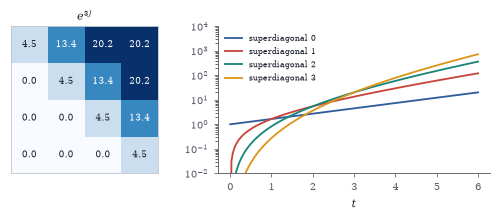

In [2]:
lam0 = 0.5; Jm4 = lam0 * np.eye(4) + np.eye(4, k=1); ts = np.linspace(0, 6, 200)
from scipy.linalg import expm
import math
E3 = expm(3 * Jm4)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9), gridspec_kw={"width_ratios": [1, 1.5]})
heat(axs[0], E3, fmt="{:.1f}", cmap="Blues", fs=6); axs[0].set_title(r"$e^{3J}$", fontsize=7)
for j in range(4): axs[1].semilogy(ts, np.exp(lam0 * ts) * ts**j / math.factorial(j) + 1e-12, color=PALETTE[j], label=f"superdiagonal {j}")
axs[1].set_xlabel("$t$"); axs[1].legend(fontsize=5.5); axs[1].set_ylim(1e-2, 1e4)

Lie–Trotter and Strang splitting for random $6\times6$ matrices $A,B$. The error $\lVert(e^{A/m}e^{B/m})^m-e^{A+B}\rVert$ decays like $1/m$ (blue) and the symmetric splitting like $1/m^2$ (red); dashed lines have slopes $-1$ and $-2$.

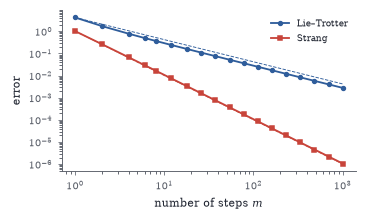

In [3]:
rng = np.random.default_rng(0); A6 = rng.normal(size=(6, 6)) / 2; B6 = rng.normal(size=(6, 6)) / 2; Eab = expm(A6 + B6)
ms = np.unique(np.logspace(0, 3, 20).astype(int)); e1, e2 = [], []
for m in ms:
    Lt = np.linalg.matrix_power(expm(A6 / m) @ expm(B6 / m), m); St = np.linalg.matrix_power(expm(A6 / (2 * m)) @ expm(B6 / m) @ expm(A6 / (2 * m)), m)
    e1.append(np.linalg.norm(Lt - Eab, 2)); e2.append(np.linalg.norm(St - Eab, 2))
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
ax.loglog(ms, e1, "o-", color=BLUE, ms=2.5, label="Lie–Trotter"); ax.loglog(ms, e2, "s-", color=RED, ms=2.5, label="Strang")
ax.loglog(ms, e1[0] / ms, "--", color=BLUE, lw=0.6); ax.loglog(ms, e2[0] / ms**2, "--", color=RED, lw=0.6); ax.set_xlabel("number of steps $m$"); ax.set_ylabel("error"); ax.legend(fontsize=6)

Loewner matrices $L_f=(f^{[1]}(\lambda_i,\lambda_j))$ for $f(t)=\sqrt t$ (left) and $f(t)=e^t$ (right) at $30$ eigenvalues spread geometrically over $[10^{-3},2]$. The square root's divided differences blow up near $0$ (top-left corner), where $\sqrt t$ has infinite slope: small perturbations of a nearly singular positive matrix can change its square root a lot. The exponential's are largest where the eigenvalues are largest.

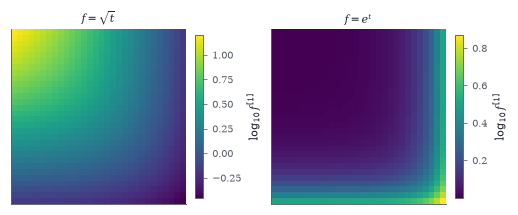

In [4]:
lamv = np.geomspace(1e-3, 2, 30)
def loewner(f, fp, lam):
    L = (f(lam)[:, None] - f(lam)[None, :]) / (lam[:, None] - lam[None, :] + np.eye(len(lam))); L[np.diag_indices(len(lam))] = fp(lam); return L
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0))
for ax, (f, fp, ttl) in zip(axs, [(np.sqrt, lambda t: 0.5 / np.sqrt(t), r"$f=\sqrt{t}$"), (np.exp, np.exp, r"$f=e^t$")]):
    im = ax.imshow(np.log10(loewner(f, fp, lamv)), cmap="viridis"); fig.colorbar(im, ax=ax, shrink=0.8, label=r"$\log_{10} f^{[1]}$"); ax.set_title(ttl, fontsize=7); ax.set_xticks([]); ax.set_yticks([])

Polynomial iterations on singular values. Left: the cubic Newton–Schulz map $s\mapsto\frac32s-\frac12s^3$ (blue) has a superattracting fixed point at $1$; the tuned quintic $3.4445s-4.7750s^3+2.0315s^5$ (red) rises much faster from small $s$ but oscillates around $1$ instead of converging. Right: singular values of a random $64\times64$ matrix (normalized to Frobenius norm $1$, so they start in $(0,0.25]$) after $k$ iterations of each map: five quintic steps put them all in a band around $1$, while the cubic takes many more steps to lift the smallest ones.

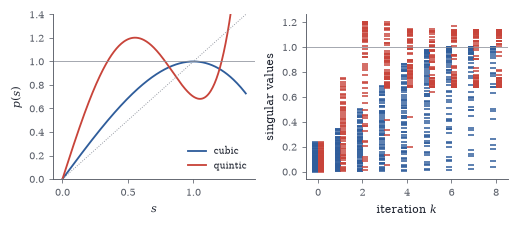

In [5]:
ss = np.linspace(0, 1.4, 300); cub = lambda s: 1.5 * s - 0.5 * s**3; qui = lambda s: 3.4445 * s - 4.7750 * s**3 + 2.0315 * s**5
rng = np.random.default_rng(1); G = rng.normal(size=(64, 64)); s0 = np.linalg.svd(G / np.linalg.norm(G), compute_uv=False)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.95))
axs[0].plot(ss, cub(ss), color=BLUE, label="cubic"); axs[0].plot(ss, qui(ss), color=RED, label="quintic"); axs[0].plot(ss, ss, color=GRAY, lw=0.6, ls=":"); axs[0].axhline(1, color=GRAY, lw=0.5)
axs[0].set_xlabel("$s$"); axs[0].set_ylabel("$p(s)$"); axs[0].legend(fontsize=6); axs[0].set_ylim(0, 1.4)
for k in range(9):
    sc, sq = s0.copy(), s0.copy()
    for _ in range(k): sc, sq = cub(sc), qui(sq)
    axs[1].plot(np.full(64, k) - 0.12, sc, "_", color=BLUE, ms=4); axs[1].plot(np.full(64, k) + 0.12, sq, "_", color=RED, ms=4)
axs[1].set_xlabel("iteration $k$"); axs[1].set_ylabel("singular values"); axs[1].axhline(1, color=GRAY, lw=0.5)

In [6]:
from scipy.linalg import sqrtm
rng = np.random.default_rng(3); Xr = rng.normal(size=(5, 5)); Ar = Xr @ Xr.T + 0.5 * np.eye(5); Hr = rng.normal(size=(5, 5)); Hr = Hr + Hr.T
lr, Uq = np.linalg.eigh(Ar); Lf = (np.sqrt(lr)[:, None] - np.sqrt(lr)[None, :]) / (lr[:, None] - lr[None, :] + np.eye(5)); Lf[np.diag_indices(5)] = 0.5 / np.sqrt(lr)
Ddk = Uq @ (Lf * (Uq.T @ Hr @ Uq)) @ Uq.T
for eps in (1e-2, 1e-4, 1e-6):
    fd = (sqrtm(Ar + eps * Hr).real - sqrtm(Ar).real) / eps; print(f"eps={eps:.0e}: ||finite difference - Daleckii-Krein|| = {np.linalg.norm(fd - Ddk):.2e}")

eps=1e-02: ||finite difference - Daleckii-Krein|| = 1.51e-02
eps=1e-04: ||finite difference - Daleckii-Krein|| = 1.51e-04
eps=1e-06: ||finite difference - Daleckii-Krein|| = 1.51e-06


In [7]:
rng = np.random.default_rng(5); A6 = rng.normal(size=(6, 6)); Xk = A6.copy()
for k in range(30):
    Xn = 0.5 * (Xk + np.linalg.inv(Xk))
    if np.linalg.norm(Xn - Xk) < 1e-13: break
    Xk = Xn
P = 0.5 * (np.eye(6) + Xn); ev = np.linalg.eigvals(A6)
print("iterations:", k, "  P^2 = P:", np.allclose(P @ P, P), "  rank P =", round(np.trace(P).real), "  eigenvalues with Re > 0:", int(np.sum(ev.real > 0)))

iterations: 7   P^2 = P: True   rank P = 2   eigenvalues with Re > 0: 2
